# Math 32 — Lecture 24: The Law of Large Numbers & The Central Limit Theorem

Companion notebook for `Lecture24.tex`. Every figure in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**: it re-imports what it needs,
so you can copy any single cell into another notebook, change a number (e.g. `N`, `n`, the seed, or the
starting distribution), and re-run it live in class. Figures are saved (white background, 200 dpi) into `figures/`.

"Student 1", "Student 2", … are just **independent simulations** (different random seeds) — nobody actually rolled anything.

| Section | What it shows | Figures saved |
|---|---|---|
| 1 | Running average of die rolls: 1 student, 2 students, 30 students | `lln_student1.png`, `lln_two_students.png`, `lln_30_students.png` |
| 2 | The "funnel": 30 running averages inside $\mu \pm 2\sigma/\sqrt{n}$ | `lln_funnel.png` |
| 3 | Caveat: the mean must exist (Pareto with $\alpha = 1$ vs. $\alpha = 3$) | `lln_pareto_caveat.png` |
| 4 | Distribution of $\bar X_n$ for a die, a coin, and Exp(1) at $n = 1, 2, 5, 30$ | `clt_xbar_die.png`, `clt_xbar_coin.png`, `clt_xbar_exp.png` |
| 5 | Standardized averages $Z_n$ vs. the $N(0,1)$ curve | `clt_z_coin.png`, `clt_z_exp.png` |

**Key formulas.** If $X_1, X_2, \dots$ are i.i.d. with mean $\mu$ and variance $\sigma^2$, and $\bar X_n = \frac1n(X_1 + \dots + X_n)$:
$$E[\bar X_n] = \mu, \qquad \mathrm{Var}(\bar X_n) = \frac{\sigma^2}{n}, \qquad Z_n = \frac{\bar X_n - \mu}{\sigma/\sqrt n}.$$

## 1. Averages vary less: running average of die rolls

A fair die has $\mu = 3.5$ and $\sigma^2 = 35/12 \approx 2.92$. The **running average** after $n$ rolls is
$\bar X_n = \frac1n(X_1 + \dots + X_n)$.

### 1a. Student 1

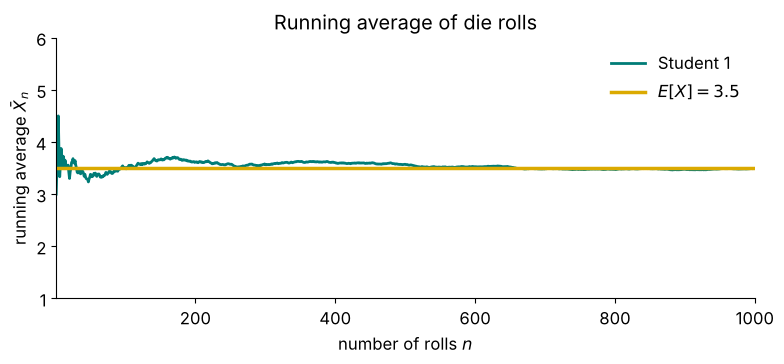

first 10 rolls: [3 4 5 6 1 1 5 6 2 2]   average after 10: 3.5   after 1000: 3.493


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(1)          # "Student 1" = seed 1
N = 1000
rolls = rng.integers(1, 7, size=N)       # N fair die rolls (1..6)
n = np.arange(1, N + 1)
running_avg = np.cumsum(rolls) / n

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(n, running_avg, color=TEAL, lw=2, label="Student 1")
ax.axhline(3.5, color=GOLD, lw=2.5, label=r"$E[X] = 3.5$")
ax.set(xlim=(1, N), ylim=(1, 6), xlabel="number of rolls $n$", ylabel=r"running average $\bar X_n$",
       title="Running average of die rolls")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUTDIR / "lln_student1.png", dpi=200, facecolor="white")
plt.show()
print("first 10 rolls:", rolls[:10], "  average after 10:", running_avg[9], "  after 1000:", running_avg[-1])

### 1b. Student 2 (an independent simulation)

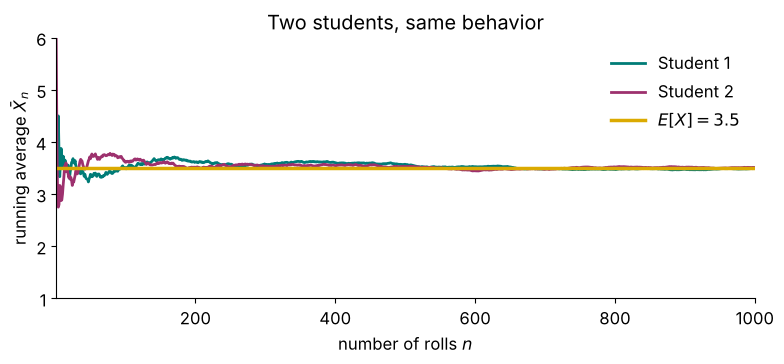

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

N = 1000
n = np.arange(1, N + 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
for seed, color, name in [(1, TEAL, "Student 1"), (2, MAGENTA, "Student 2")]:
    rolls = np.random.default_rng(seed).integers(1, 7, size=N)
    ax.plot(n, np.cumsum(rolls) / n, color=color, lw=2, label=name)
ax.axhline(3.5, color=GOLD, lw=2.5, label=r"$E[X] = 3.5$")
ax.set(xlim=(1, N), ylim=(1, 6), xlabel="number of rolls $n$", ylabel=r"running average $\bar X_n$",
       title="Two students, same behavior")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUTDIR / "lln_two_students.png", dpi=200, facecolor="white")
plt.show()

### 1c. 30 students (30 independent simulations)

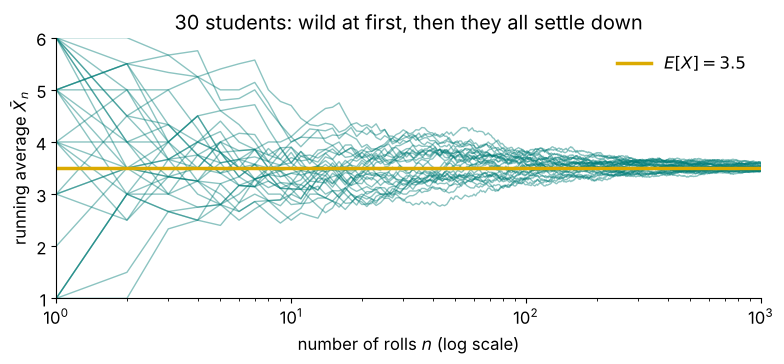

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

N, m = 1000, 30
n = np.arange(1, N + 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
for seed in range(1, m + 1):
    rolls = np.random.default_rng(seed).integers(1, 7, size=N)
    ax.plot(n, np.cumsum(rolls) / n, color=TEAL, lw=1, alpha=0.45)
ax.axhline(3.5, color=GOLD, lw=2.5, label=r"$E[X] = 3.5$")
ax.set(xscale="log", xlim=(1, N), ylim=(1, 6), xlabel="number of rolls $n$ (log scale)",
       ylabel=r"running average $\bar X_n$", title="30 students: wild at first, then they all settle down")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUTDIR / "lln_30_students.png", dpi=200, facecolor="white")
plt.show()

## 2. The funnel: $\bar X_n$ stays within $\mu \pm 2\sigma/\sqrt{n}$ most of the time

Since $\mathrm{SD}(\bar X_n) = \sigma/\sqrt n$, the spread of the running averages shrinks like $1/\sqrt n$.

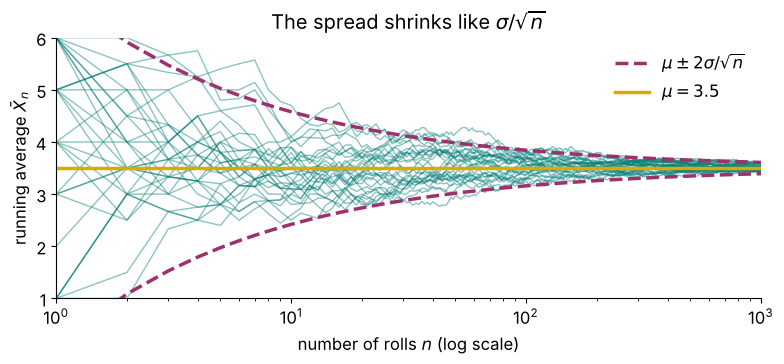

n = 100: fraction of the 30 students outside mu ± 2 sigma/sqrt(n) = 0.00  (Chebyshev guarantees <= 0.25)
n = 1000: fraction of the 30 students outside mu ± 2 sigma/sqrt(n) = 0.03  (Chebyshev guarantees <= 0.25)


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

N, m = 1000, 30
mu, sigma = 3.5, np.sqrt(35 / 12)
n = np.arange(1, N + 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
for seed in range(1, m + 1):
    rolls = np.random.default_rng(seed).integers(1, 7, size=N)
    ax.plot(n, np.cumsum(rolls) / n, color=TEAL, lw=1, alpha=0.45)
ax.plot(n, mu + 2 * sigma / np.sqrt(n), color=MAGENTA, lw=2.5, ls="--", label=r"$\mu \pm 2\sigma/\sqrt{n}$")
ax.plot(n, mu - 2 * sigma / np.sqrt(n), color=MAGENTA, lw=2.5, ls="--")
ax.axhline(mu, color=GOLD, lw=2.5, label=r"$\mu = 3.5$")
ax.set(xscale="log", xlim=(1, N), ylim=(1, 6), xlabel="number of rolls $n$ (log scale)",
       ylabel=r"running average $\bar X_n$", title=r"The spread shrinks like $\sigma/\sqrt{n}$")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUTDIR / "lln_funnel.png", dpi=200, facecolor="white")
plt.show()

# how often is each running average outside the funnel, at n = 100 and n = 1000?
avgs = np.array([np.cumsum(np.random.default_rng(s).integers(1, 7, size=N)) / n for s in range(1, m + 1)])
for k in (100, 1000):
    out = np.mean(np.abs(avgs[:, k - 1] - mu) >= 2 * sigma / np.sqrt(k))
    print(f"n = {k}: fraction of the 30 students outside mu ± 2 sigma/sqrt(n) = {out:.2f}  (Chebyshev guarantees <= 0.25)")

## 3. Caveat: the mean has to exist

Pareto($\alpha$) on $x \ge 1$ has $E[X] = \alpha/(\alpha - 1)$ for $\alpha > 1$, but **$E[X] = \infty$ for $\alpha = 1$**.
With $\alpha = 3$ the running averages settle at $1.5$; with $\alpha = 1$ they never settle — every so often a huge value
drags the average up. (Sampling: if $U \sim U(0,1)$ then $U^{-1/\alpha}$ has the Pareto($\alpha$) distribution.)

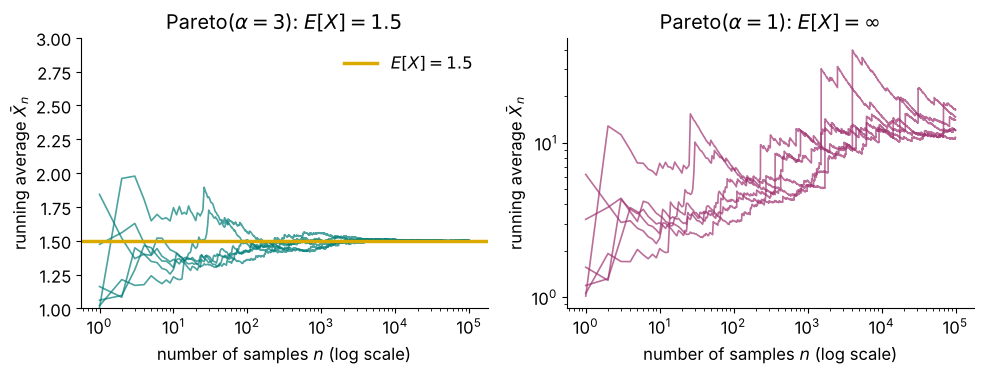

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

N, m = 100_000, 6
n = np.arange(1, N + 1)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.9), sharex=True)
for ax, alpha, title in [(axs[0], 3, r"Pareto($\alpha=3$): $E[X] = 1.5$"), (axs[1], 1, r"Pareto($\alpha=1$): $E[X] = \infty$")]:
    for seed in range(1, m + 1):
        x = np.random.default_rng(100 + seed).random(N) ** (-1 / alpha)
        ax.plot(n, np.cumsum(x) / n, lw=1.2, color=TEAL if alpha == 3 else MAGENTA, alpha=0.7)
    if alpha == 3:
        ax.axhline(1.5, color=GOLD, lw=2.5, label=r"$E[X] = 1.5$")
        ax.set_ylim(1, 3); ax.legend(frameon=False)
    else:
        ax.set_yscale("log")
    ax.set(xscale="log", xlabel="number of samples $n$ (log scale)", ylabel=r"running average $\bar X_n$", title=title)
fig.tight_layout()
fig.savefig(OUTDIR / "lln_pareto_caveat.png", dpi=200, facecolor="white")
plt.show()

## 4. The shape of $\bar X_n$: averages look normal

For each $n$ we simulate $\bar X_n$ **200,000 times** and draw its histogram. Three very different starting
distributions — a die (flat), a fair coin (two spikes), and Exp(1) (very skewed) — all turn into a bell shape.

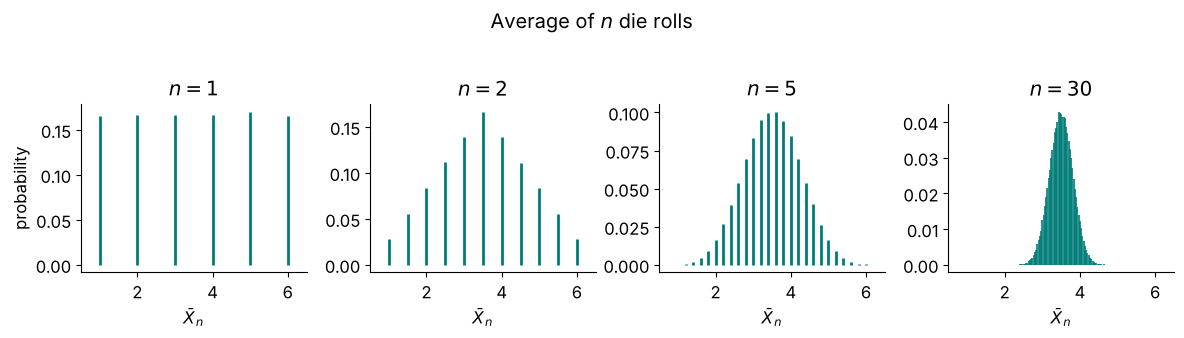

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(24)
reps = 200_000
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, n in zip(axs, [1, 2, 5, 30]):
    xbar = rng.integers(1, 7, size=(reps, n)).mean(axis=1)
    vals, counts = np.unique(np.round(xbar, 8), return_counts=True)
    ax.vlines(vals, 0, counts / reps, color=TEAL, lw=2 if n < 30 else 1.2)
    ax.set(xlim=(0.5, 6.5), title=f"$n = {n}$", xlabel=r"$\bar X_n$")
axs[0].set_ylabel("probability")
fig.suptitle("Average of $n$ die rolls", y=1.02)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_xbar_die.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

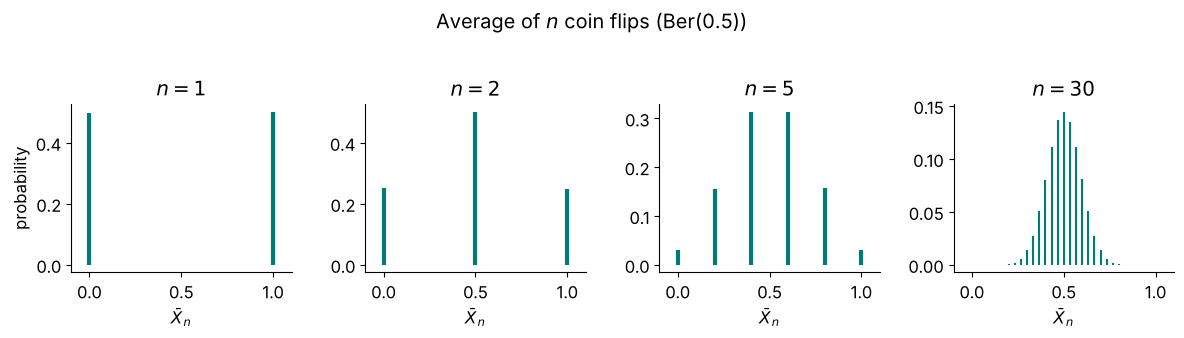

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(25)
reps = 200_000
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, n in zip(axs, [1, 2, 5, 30]):
    xbar = (rng.random((reps, n)) < 0.5).mean(axis=1)       # n fair coin flips, heads = 1
    vals, counts = np.unique(np.round(xbar, 8), return_counts=True)
    ax.vlines(vals, 0, counts / reps, color=TEAL, lw=3 if n < 30 else 1.5)
    ax.set(xlim=(-0.1, 1.1), title=f"$n = {n}$", xlabel=r"$\bar X_n$")
axs[0].set_ylabel("probability")
fig.suptitle("Average of $n$ coin flips (Ber(0.5))", y=1.02)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_xbar_coin.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

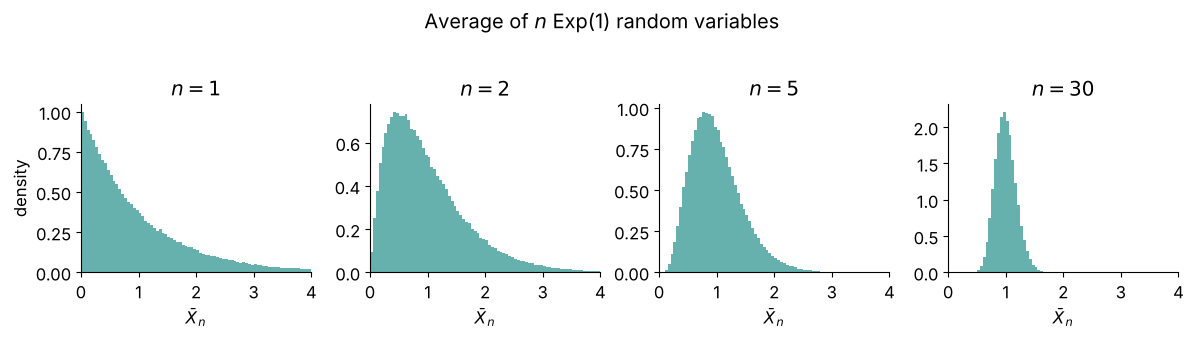

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(26)
reps = 200_000
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, n in zip(axs, [1, 2, 5, 30]):
    xbar = rng.exponential(1.0, size=(reps, n)).mean(axis=1)
    ax.hist(xbar, bins=80, range=(0, 4), density=True, color=TEAL, alpha=0.6)
    ax.set(xlim=(0, 4), title=f"$n = {n}$", xlabel=r"$\bar X_n$")
axs[0].set_ylabel("density")
fig.suptitle("Average of $n$ Exp(1) random variables", y=1.02)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_xbar_exp.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## 5. Standardize: $Z_n = \dfrac{\bar X_n - \mu}{\sigma/\sqrt n}$ — compare with the $N(0,1)$ curve

Standardizing removes the shrinking: $E[Z_n] = 0$ and $\mathrm{Var}(Z_n) = 1$ for every $n$.
The CLT says the **shape** of $Z_n$ approaches the standard normal.

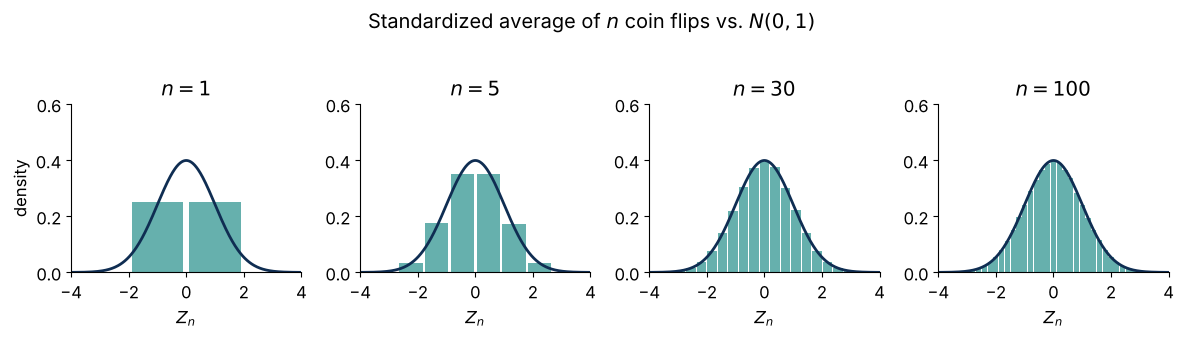

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

from math import sqrt, pi
rng = np.random.default_rng(27)
reps = 200_000
mu, sigma = 0.5, 0.5                                       # Ber(0.5)
zz = np.linspace(-4, 4, 400); phi = np.exp(-zz**2 / 2) / sqrt(2 * pi)
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, n in zip(axs, [1, 5, 30, 100]):
    z = ((rng.random((reps, n)) < 0.5).mean(axis=1) - mu) / (sigma / np.sqrt(n))
    vals, counts = np.unique(np.round(z, 8), return_counts=True)
    width = 1 / (sigma * np.sqrt(n))                        # spacing between possible Z values
    ax.bar(vals, counts / reps / width, width=width * 0.9, color=TEAL, alpha=0.6)
    ax.plot(zz, phi, color=NAVY, lw=2)
    ax.set(xlim=(-4, 4), ylim=(0, 0.6), title=f"$n = {n}$", xlabel="$Z_n$")
axs[0].set_ylabel("density")
fig.suptitle("Standardized average of $n$ coin flips vs. $N(0,1)$", y=1.02)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_z_coin.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

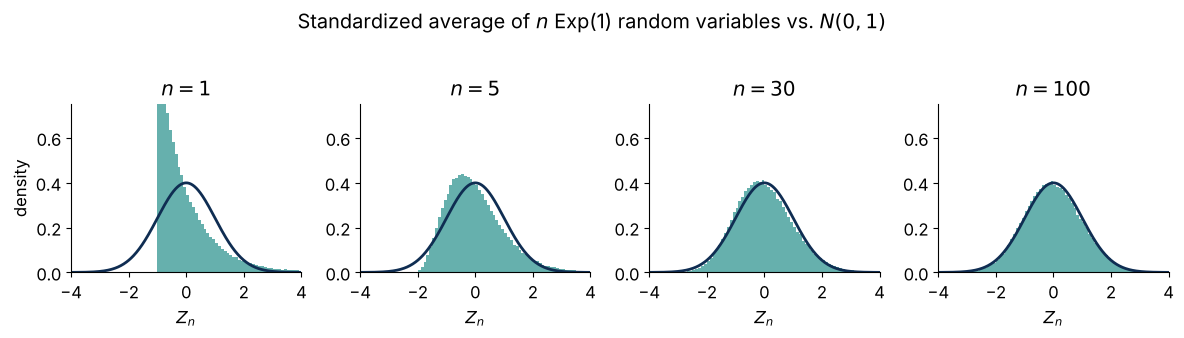

n =   1:  P(Z_n <= 1) = 0.8662   (Phi(1) = 0.8413)
n =   5:  P(Z_n <= 1) = 0.8472   (Phi(1) = 0.8413)
n =  30:  P(Z_n <= 1) = 0.8435   (Phi(1) = 0.8413)


n = 100:  P(Z_n <= 1) = 0.8406   (Phi(1) = 0.8413)


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

from math import sqrt, pi
rng = np.random.default_rng(28)
reps = 200_000
mu, sigma = 1.0, 1.0                                       # Exp(1)
zz = np.linspace(-4, 4, 400); phi = np.exp(-zz**2 / 2) / sqrt(2 * pi)
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, n in zip(axs, [1, 5, 30, 100]):
    z = (rng.exponential(1.0, size=(reps, n)).mean(axis=1) - mu) / (sigma / np.sqrt(n))
    ax.hist(z, bins=80, range=(-4, 4), density=True, color=TEAL, alpha=0.6)
    ax.plot(zz, phi, color=NAVY, lw=2)
    ax.set(xlim=(-4, 4), ylim=(0, 0.75), title=f"$n = {n}$", xlabel="$Z_n$")
axs[0].set_ylabel("density")
fig.suptitle("Standardized average of $n$ Exp(1) random variables vs. $N(0,1)$", y=1.02)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_z_exp.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

# numerical check: P(Z_n <= 1) vs Phi(1) = 0.8413
for n in [1, 5, 30, 100]:
    z = (np.random.default_rng(n).exponential(1.0, size=(reps, n)).mean(axis=1) - 1) * np.sqrt(n)
    print(f"n = {n:3d}:  P(Z_n <= 1) = {np.mean(z <= 1):.4f}   (Phi(1) = 0.8413)")